# Лабораторная работа 3. Кластеризация

## Введение

### Цель работы
Изучение алгоритмов кластеризации, приобретение навыков оценки качества разбиения данных на кластеры и интерпретации результатов.

### Постановка задачи

1. Загрузить датасет для задачи кластеризации / классификации (например, с платформы Kaggle). Провести дескриптивный анализ данных: определить размерность, типы признаков, наличие пропусков. Оценить распределение переменных (близость к нормальному) с использованием визуализации (гистограммы). Оценить информационную значимость признаков. Проверить условие применения кластеризации: отсутствие классов, осмысленность кластеризации, отсутствие выбросов.

2. Выполнить стандартизацию / нормализацию числовых признаков. Обосновать выбор метода масштабирования. Построить матрицу диаграмм рассеивания для визуальной оценки структуры данных, предположительного количества кластеров и типа кластерной структуры. Аргументировать выбор методов кластеризации на основе формы, размера и плотности кластеров.

3. Реализовать кластеризацию двумя различными методами на выбор: K-means (K-средних); иерархическая кластеризация; DBSCAN; EM-алгоритм (Gaussian Mixture). Для методов, требующих задания числа кластеров (K-means, иерархическая), подобрать оптимальное значение k с использованием: метода локтя и / или анализа силуэта.

4. Рассчитать метрики качества для обоих методов: внутренние и внешние. Оценить расстояние между кластерами, внутрикластерные расстояния, компактность кластеров, центры кластеров. Опционально, если известно разделение на классы, посчитать: индекс Rand, индекс Жаккара и др. внешние метрики. Привести содержательную интерпретацию полученных значений.

5. Исследовать влияние параметров одного из методов (например, ε и min_samples для DBSCAN или количества кластеров k для K-means) на качество кластеризации.

6. Визуализировать полученные кластеры в пространстве признаков (использовать PCA для снижения размерности при необходимости). Проанализировать центры кластеров и дать содержательную интерпретацию выделенных групп. Сравнить результаты, полученные двумя разными методами.

## Описание датасета

Используется набор данных seed.csv. Он содержит измерения характеристик зерен трех разновидностей пшеницы: Kama, Rosa и Canadian. В исходном наборе 210 наблюдений: по 70 наблюдений каждого вида. Для каждого зерна записаны семь непрерывных числовых характеристик и одна исходная метка разновидности.

1. AREA - площадь зерна, числовой признак
2. PERIMETER - периметр зерна, числовой признак
3. COMPACTNESS - компактность зерна (в исходном наборе рассчитывается как 4π·AREA/PERIMETER²), числовой признак
4. LENGTH - длина зерна, числовой признак
5. WIDTH - ширина зерна, числовой признак
6. ASSYMMETRY_COEFFICIENT - коэффициент асимметрии, числовой признак
7. GROOVE_LENGTH - длина бороздки зерна, числовой признак
8. TYPE - исходная разновидность: 1 - Kama, 2 - Rosa, 3 - Canadian; только внешняя проверка, в кластеризацию не включается

### Импорт библиотек

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import shapiro, skew
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import pdist, cdist
from scipy.optimize import linear_sum_assignment
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import f_classif
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score, calinski_harabasz_score, davies_bouldin_score,
    adjusted_rand_score, adjusted_mutual_info_score,
    normalized_mutual_info_score, rand_score, fowlkes_mallows_score
)
from sklearn.decomposition import PCA
from IPython.display import display

### Загрузка датасета

In [8]:
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 10

DATA_PATH = Path('seed.csv')

df = pd.read_csv(DATA_PATH)
EXPECTED_COLUMNS = [
    'AREA', 'PERIMETER', 'COMPACTNESS', 'LENGTH', 'WIDTH',
    'ASSYMMETRY_COEFFICIENT', 'GROOVE_LENGTH', 'TYPE'
]

FEATURES = EXPECTED_COLUMNS[:-1]
TARGET = 'TYPE'
CLASS_NAMES = {1: 'Kama', 2: 'Rosa', 3: 'Canadian'}
X = df[FEATURES].copy()       
y_reference = df[TARGET].astype(int).copy()  #

print('Первые пять строк датасета:')
display(df.head())
print(f'Размерность датасета: {df.shape[0]} строк × {df.shape[1]} столбцов')
print(f'Число объектов: {len(df)}')
print(f'Число числовых признаков для кластеризации: {len(FEATURES)}')
print(f'Наличие пропусков: {df.isna().sum().sum()}')
print(f'Количество полностью повторяющихся строк: {df.duplicated().sum()}')
print('\nТипы данных:')
display(df.dtypes.rename('Тип данных').to_frame())
print('\nЧисло объектов каждого исходного типа:')
class_counts = y_reference.map(CLASS_NAMES).value_counts().reindex(['Kama', 'Rosa', 'Canadian'])
display(class_counts.rename('Количество объектов').to_frame())

Первые пять строк датасета:


,AREA,PERIMETER,COMPACTNESS,LENGTH,WIDTH,ASSYMMETRY_COEFFICIENT,GROOVE_LENGTH,TYPE
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1


Размерность датасета: 210 строк × 8 столбцов
Число объектов: 210
Число числовых признаков для кластеризации: 7
Наличие пропусков: 0
Количество полностью повторяющихся строк: 0

Типы данных:


,Тип данных
AREA,float64
PERIMETER,float64
COMPACTNESS,float64
LENGTH,float64
WIDTH,float64
ASSYMMETRY_COEFFICIENT,float64
GROOVE_LENGTH,float64
TYPE,int64



Число объектов каждого исходного типа:


,Количество объектов
TYPE,
Kama,70
Rosa,70
Canadian,70


По результатам загрузки в датасете 210 строк и 8 столбцов: семь признаков имеют числовой тип, TYPE - целочисленная категория. Пропущенных значений и полностью повторяющихся строк нет. В каждой из трех исходных категорий находится по 70 зерен, то есть классы сбалансированы.

### Дескрептивный анализ

In [3]:
summary = X.describe().T
summary['Медиана'] = X.median()
summary['Асимметрия распределения'] = X.apply(skew)
summary = summary[['count', 'mean', 'Медиана', 'std', 'min', '25%', '50%', '75%', 'max', 'Асимметрия распределения']]
summary = summary.rename(columns={
    'count': 'Количество', 'mean': 'Среднее', 'std': 'Станд. отклонение',
    'min': 'Минимум', '25%': 'Q1', '50%': 'Медиана (Q2)', '75%': 'Q3', 'max': 'Максимум'
})
display(summary.round(4))

print('Диапазоны значений признаков:')
ranges = pd.DataFrame({'Минимум': X.min(), 'Максимум': X.max(), 'Размах': X.max() - X.min()})
display(ranges.round(4))

,Количество,Среднее,Медиана,Станд. отклонение,Минимум,Q1,Медиана (Q2),Q3,Максимум,Асимметрия распределения
AREA,210.0,14.8475,14.3550,2.9097,10.5900,12.2700,14.3550,17.3050,21.1800,0.3970
PERIMETER,210.0,14.5593,14.3200,1.3060,12.4100,13.4500,14.3200,15.7150,17.2500,0.3838
COMPACTNESS,210.0,0.8710,0.8734,0.0236,0.8081,0.8569,0.8734,0.8878,0.9183,-0.5341
LENGTH,210.0,5.6285,5.5235,0.4431,4.8990,5.2622,5.5235,5.9798,6.6750,0.5217
WIDTH,210.0,3.2586,3.2370,0.3777,2.6300,2.9440,3.2370,3.5618,4.0330,0.1334
ASSYMMETRY_COEFFICIENT,210.0,3.7002,3.5990,1.5036,0.7651,2.5615,3.5990,4.7688,8.4560,0.3988
GROOVE_LENGTH,210.0,5.4081,5.2230,0.4915,4.5190,5.0450,5.2230,5.8770,6.5500,0.5579


Диапазоны значений признаков:


,Минимум,Максимум,Размах
AREA,10.5900,21.1800,10.5900
PERIMETER,12.4100,17.2500,4.8400
COMPACTNESS,0.8081,0.9183,0.1102
LENGTH,4.8990,6.6750,1.7760
WIDTH,2.6300,4.0330,1.4030
ASSYMMETRY_COEFFICIENT,0.7651,8.4560,7.6909
GROOVE_LENGTH,4.5190,6.5500,2.0310


### Распределение признаков

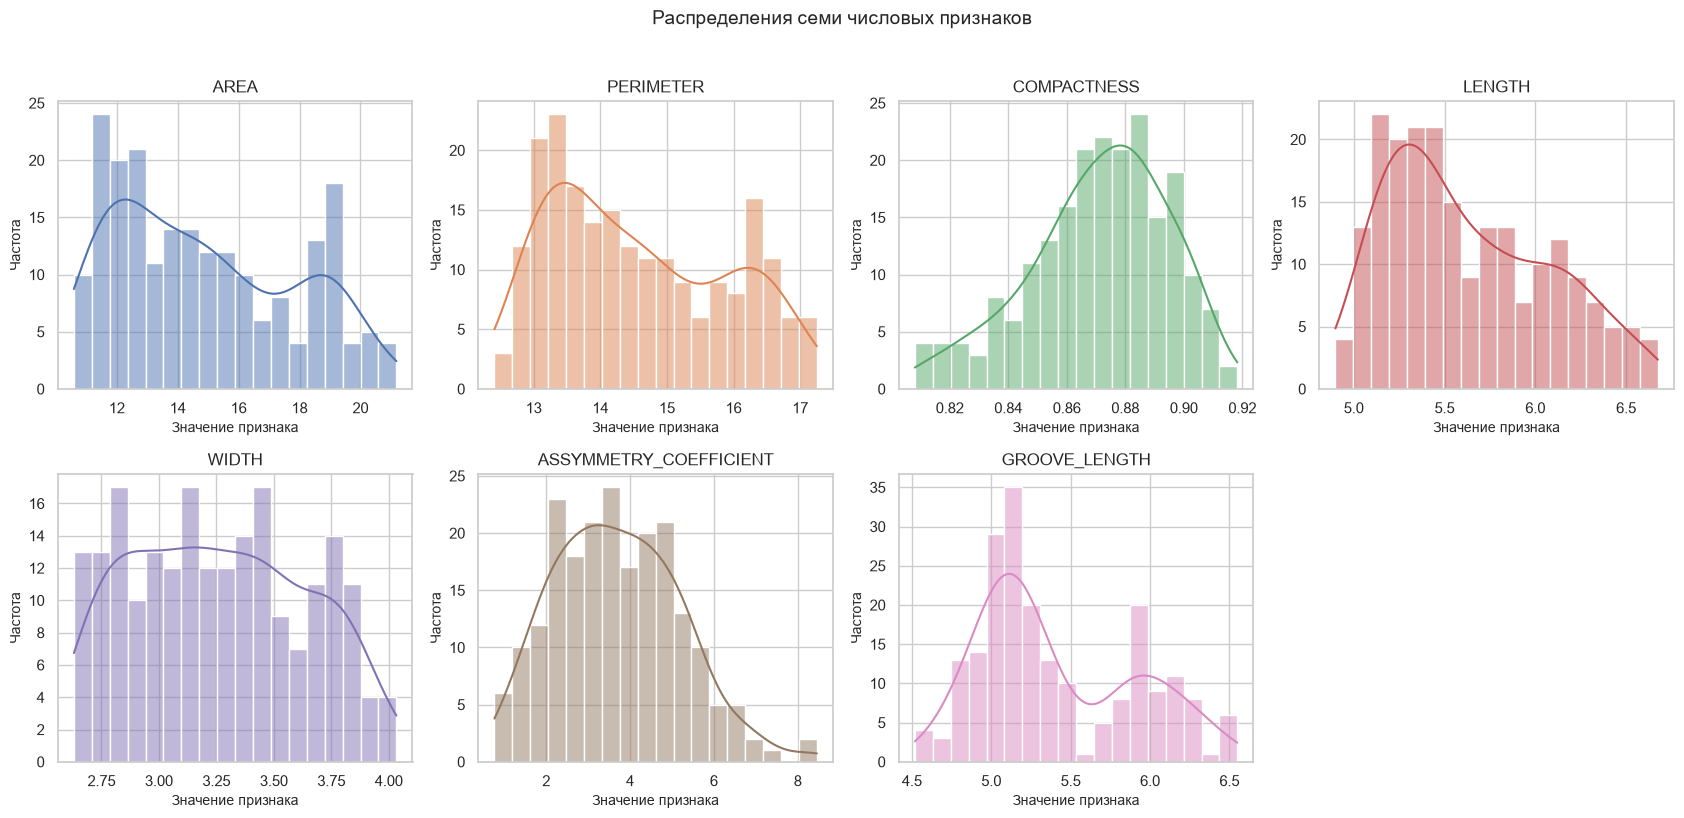

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(17, 8))
axes = axes.ravel()
for i, feature in enumerate(FEATURES):
    sns.histplot(X[feature], kde=True, bins=18, ax=axes[i], color=sns.color_palette()[i])
    axes[i].set_title(feature)
    axes[i].set_xlabel('Значение признака')
    axes[i].set_ylabel('Частота')
axes[-1].axis('off')
fig.suptitle('Распределения семи числовых признаков', y=1.02, fontsize=14)
plt.tight_layout()
plt.show()


###  Диаграммы размаха

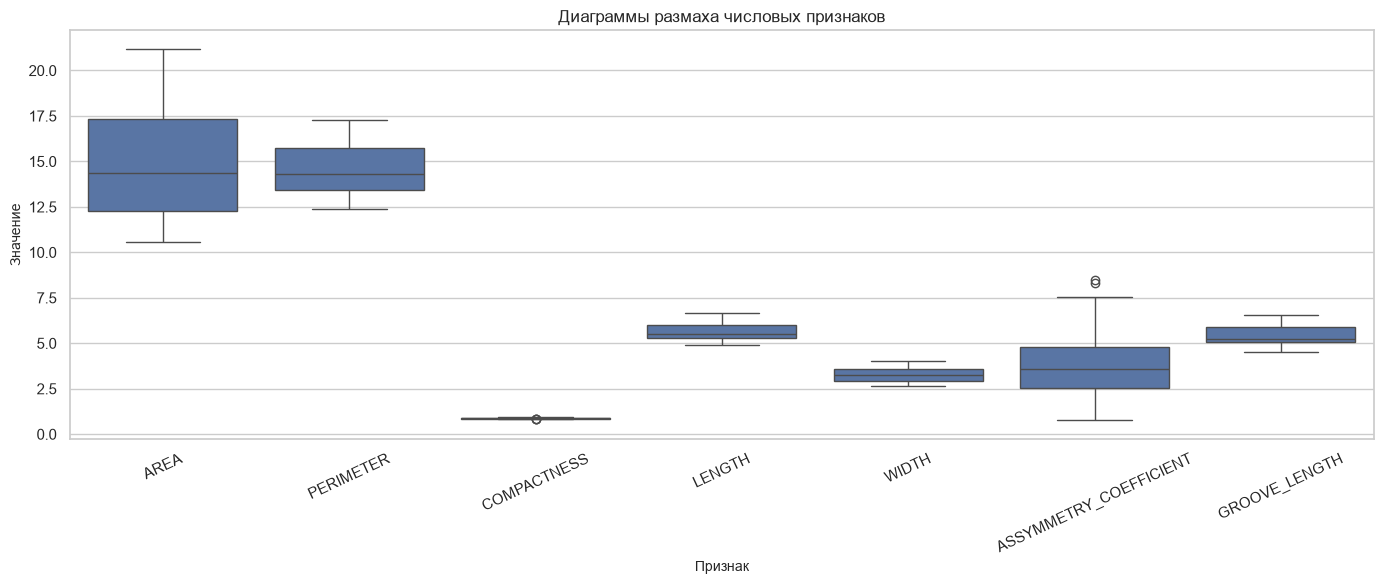

Потенциальные выбросы по каждому признаку (правило 1,5 × IQR):


,Признак,Q1,Q3,IQR,Нижняя граница,Верхняя граница,Потенциальных выбросов
0,AREA,12.27000,17.30500,5.03500,4.71750,24.85750,0
1,PERIMETER,13.45000,15.71500,2.26500,10.05250,19.11250,0
2,COMPACTNESS,0.85690,0.88778,0.03087,0.81059,0.93409,3
3,LENGTH,5.26225,5.97975,0.71750,4.18600,7.05600,0
4,WIDTH,2.94400,3.56175,0.61775,2.01738,4.48837,0
5,ASSYMMETRY_COEFFICIENT,2.56150,4.76875,2.20725,-0.74937,8.07962,2
6,GROOVE_LENGTH,5.04500,5.87700,0.83200,3.79700,7.12500,0


Количество уникальных строк, в которых отмечен хотя бы один потенциальный выброс: 5 из 210
Номера отмеченных наблюдений (нумерация с 1): [158, 159, 175, 204, 208]


,AREA,PERIMETER,COMPACTNESS,LENGTH,WIDTH,ASSYMMETRY_COEFFICIENT,GROOVE_LENGTH,TYPE
157,12.13,13.73,0.8081,5.394,2.745,4.825,5.220,3
158,11.75,13.52,0.8082,5.444,2.678,4.378,5.310,3
174,10.83,12.96,0.8099,5.278,2.641,5.182,5.185,3
203,12.70,13.41,0.8874,5.183,3.091,8.456,5.000,3
207,13.20,13.66,0.8883,5.236,3.232,8.315,5.056,3


In [7]:
# 2.4. Диаграммы размаха и поиск потенциальных выбросов методом IQR
fig, ax = plt.subplots(figsize=(14, 6))
long_X = X.melt(var_name='Признак', value_name='Значение')
sns.boxplot(data=long_X, x='Признак', y='Значение', ax=ax)
ax.set_title('Диаграммы размаха числовых признаков')
ax.tick_params(axis='x', rotation=25)
plt.tight_layout()
plt.show()

outlier_rows = []
outlier_masks = []
for feature in FEATURES:
    q1 = X[feature].quantile(0.25)
    q3 = X[feature].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = (X[feature] < lower) | (X[feature] > upper)
    outlier_masks.append(mask)
    outlier_rows.append({
        'Признак': feature,
        'Q1': q1,
        'Q3': q3,
        'IQR': iqr,
        'Нижняя граница': lower,
        'Верхняя граница': upper,
        'Потенциальных выбросов': int(mask.sum())
    })
outlier_df = pd.DataFrame(outlier_rows)
row_outlier_mask = pd.concat(outlier_masks, axis=1).any(axis=1)
print('Потенциальные выбросы по каждому признаку (правило 1,5 × IQR):')
display(outlier_df.round(5))
print(f'Количество уникальных строк, в которых отмечен хотя бы один потенциальный выброс: {row_outlier_mask.sum()} из {len(df)}')
if row_outlier_mask.any():
    print('Номера отмеченных наблюдений (нумерация с 1):', (np.where(row_outlier_mask)[0] + 1).tolist())
    display(df.loc[row_outlier_mask, FEATURES + [TARGET]].round(4))

### Информационная значимость признаков

Для дополнительной того, насколько отдельные характеристики различаются между известными разновидностями, используется однофакторный ANOVA F-критерий. Чем выше F-статистика, тем больше межгрупповая вариация признака по отношению к внутригрупповой. Малое p-value указывает на статистически значимые различия средних значений между категориями.

,Признак,F-критерий,p-value,"Значимость при α=0,05"
0,AREA,548.186479,0.0,Статистически значимые различия
1,PERIMETER,541.579497,0.0,Статистически значимые различия
2,WIDTH,406.302031,0.0,Статистически значимые различия
3,GROOVE_LENGTH,368.950045,0.0,Статистически значимые различия
4,LENGTH,322.185934,0.0,Статистически значимые различия
5,COMPACTNESS,75.869048,0.0,Статистически значимые различия
6,ASSYMMETRY_COEFFICIENT,51.888109,0.0,Статистически значимые различия


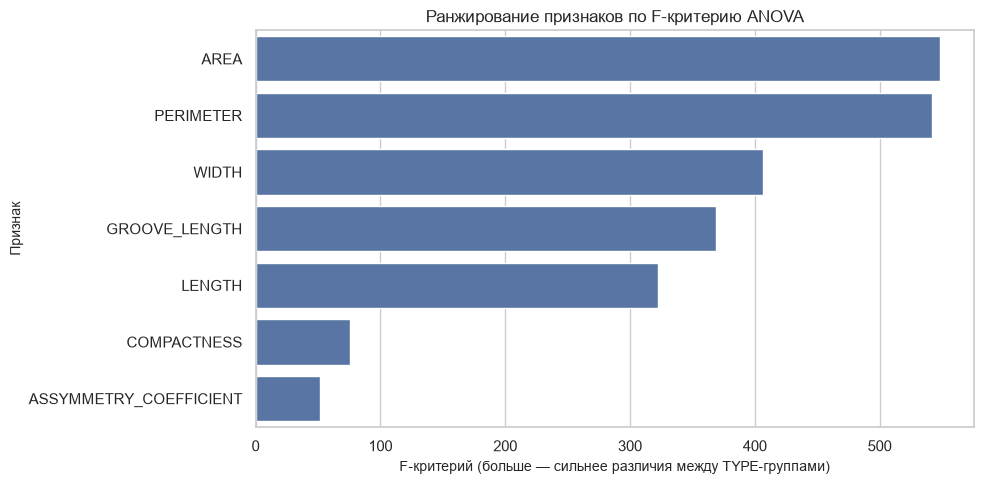

In [ ]:
f_values, p_values = f_classif(X, y_reference)
feature_significance = pd.DataFrame({
    'Признак': FEATURES,
    'F-критерий': f_values,
    'p-value': p_values
}).sort_values('F-критерий', ascending=False).reset_index(drop=True)
feature_significance['Значимость при α=0,05'] = np.where(
    feature_significance['p-value'] < 0.05, 'Статистически значимые различия', 'Не выявлены значимые различия'
)
display(feature_significance.round(6))

plt.figure(figsize=(10, 5))
sns.barplot(data=feature_significance, x='F-критерий', y='Признак', color=sns.color_palette()[0])
plt.title('Ранжирование признаков по F-критерию ANOVA')
plt.xlabel('F-критерий (больше — сильнее различия между TYPE-группами)')
plt.ylabel('Признак')
plt.tight_layout()
plt.show()

Наибольшие значения F-критерия получены для AREA (примерно 548,19) и PERIMETER (примерно 541,58). Далее следуют WIDTH (около 406,30), GROOVE_LENGTH (около 368,95) и LENGTH (около 322,19). Самые низкие F-значения у COMPACTNESS (около 75,87) и ASSYMMETRY_COEFFICIENT (около 51,89), однако и для них различия между исходными разновидностями статистически значимы (p-value < 0,05). Следовательно, все семь измерений содержат информацию о различиях групп, но площадь и периметр дают наиболее выраженное разделение по исходным типам.

## Предобработка данных